In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("ids.csv")

df.head(10)

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,class
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal
1,0,udp,other,SF,146,0,0,0,0,0,...,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal
2,0,tcp,private,S0,0,0,0,0,0,0,...,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,anomaly
3,0,tcp,http,SF,232,8153,0,0,0,0,...,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal
4,0,tcp,http,SF,199,420,0,0,0,0,...,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal
5,0,tcp,private,REJ,0,0,0,0,0,0,...,19,0.07,0.07,0.00,0.00,0.00,0.00,1.00,1.00,anomaly
6,0,tcp,private,S0,0,0,0,0,0,0,...,9,0.04,0.05,0.00,0.00,1.00,1.00,0.00,0.00,anomaly
7,0,tcp,private,S0,0,0,0,0,0,0,...,15,0.06,0.07,0.00,0.00,1.00,1.00,0.00,0.00,anomaly
8,0,tcp,remote_job,S0,0,0,0,0,0,0,...,23,0.09,0.05,0.00,0.00,1.00,1.00,0.00,0.00,anomaly
9,0,tcp,private,S0,0,0,0,0,0,0,...,13,0.05,0.06,0.00,0.00,1.00,1.00,0.00,0.00,anomaly


In [3]:
df.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25192 entries, 0 to 25191
Data columns (total 42 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   duration                     25192 non-null  int64  
 1   protocol_type                25192 non-null  object 
 2   service                      25192 non-null  object 
 3   flag                         25192 non-null  object 
 4   src_bytes                    25192 non-null  int64  
 5   dst_bytes                    25192 non-null  int64  
 6   land                         25192 non-null  int64  
 7   wrong_fragment               25192 non-null  int64  
 8   urgent                       25192 non-null  int64  
 9   hot                          25192 non-null  int64  
 10  num_failed_logins            25192 non-null  int64  
 11  logged_in                    25192 non-null  int64  
 12  num_compromised              25192 non-null  int64  
 13  root_shell      

# Simple Visuals

In [6]:
import matplotlib.pyplot as plt
protocol_map = df['protocol_type'].value_counts()

protocol_dict = protocol_map.to_dict()

Text(0, 0.5, 'count')

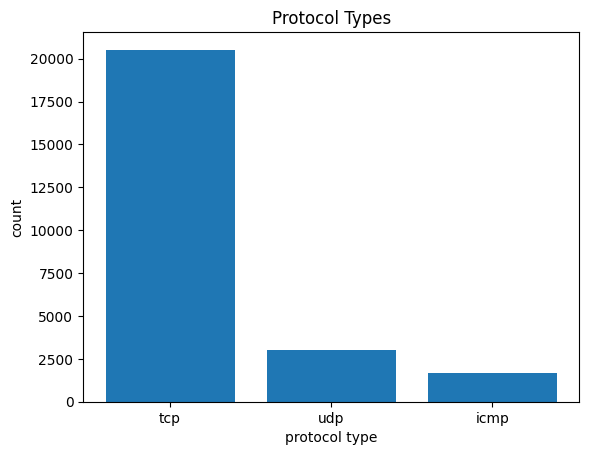

In [7]:
plt.bar(protocol_dict.keys(),protocol_dict.values())
plt.title('Protocol Types')
plt.xlabel('protocol type')
plt.ylabel('count')

Text(0, 0.5, 'flag type')

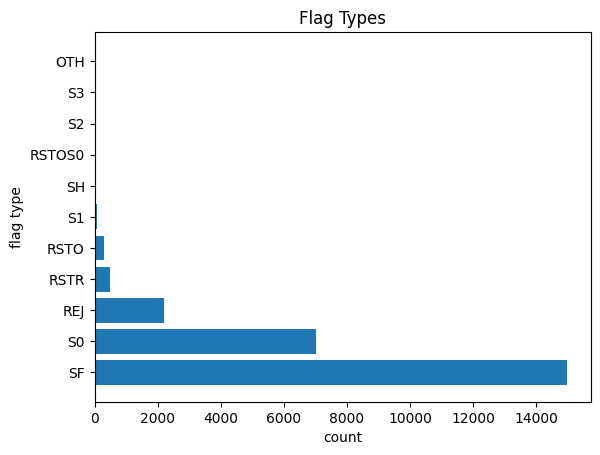

In [8]:
flag_dict = df['flag'].value_counts().to_dict()

plt.barh(flag_dict.keys(),flag_dict.values())
plt.title('Flag Types')
plt.xlabel('count')
plt.ylabel('flag type')

Text(0, 0.5, 'service type')

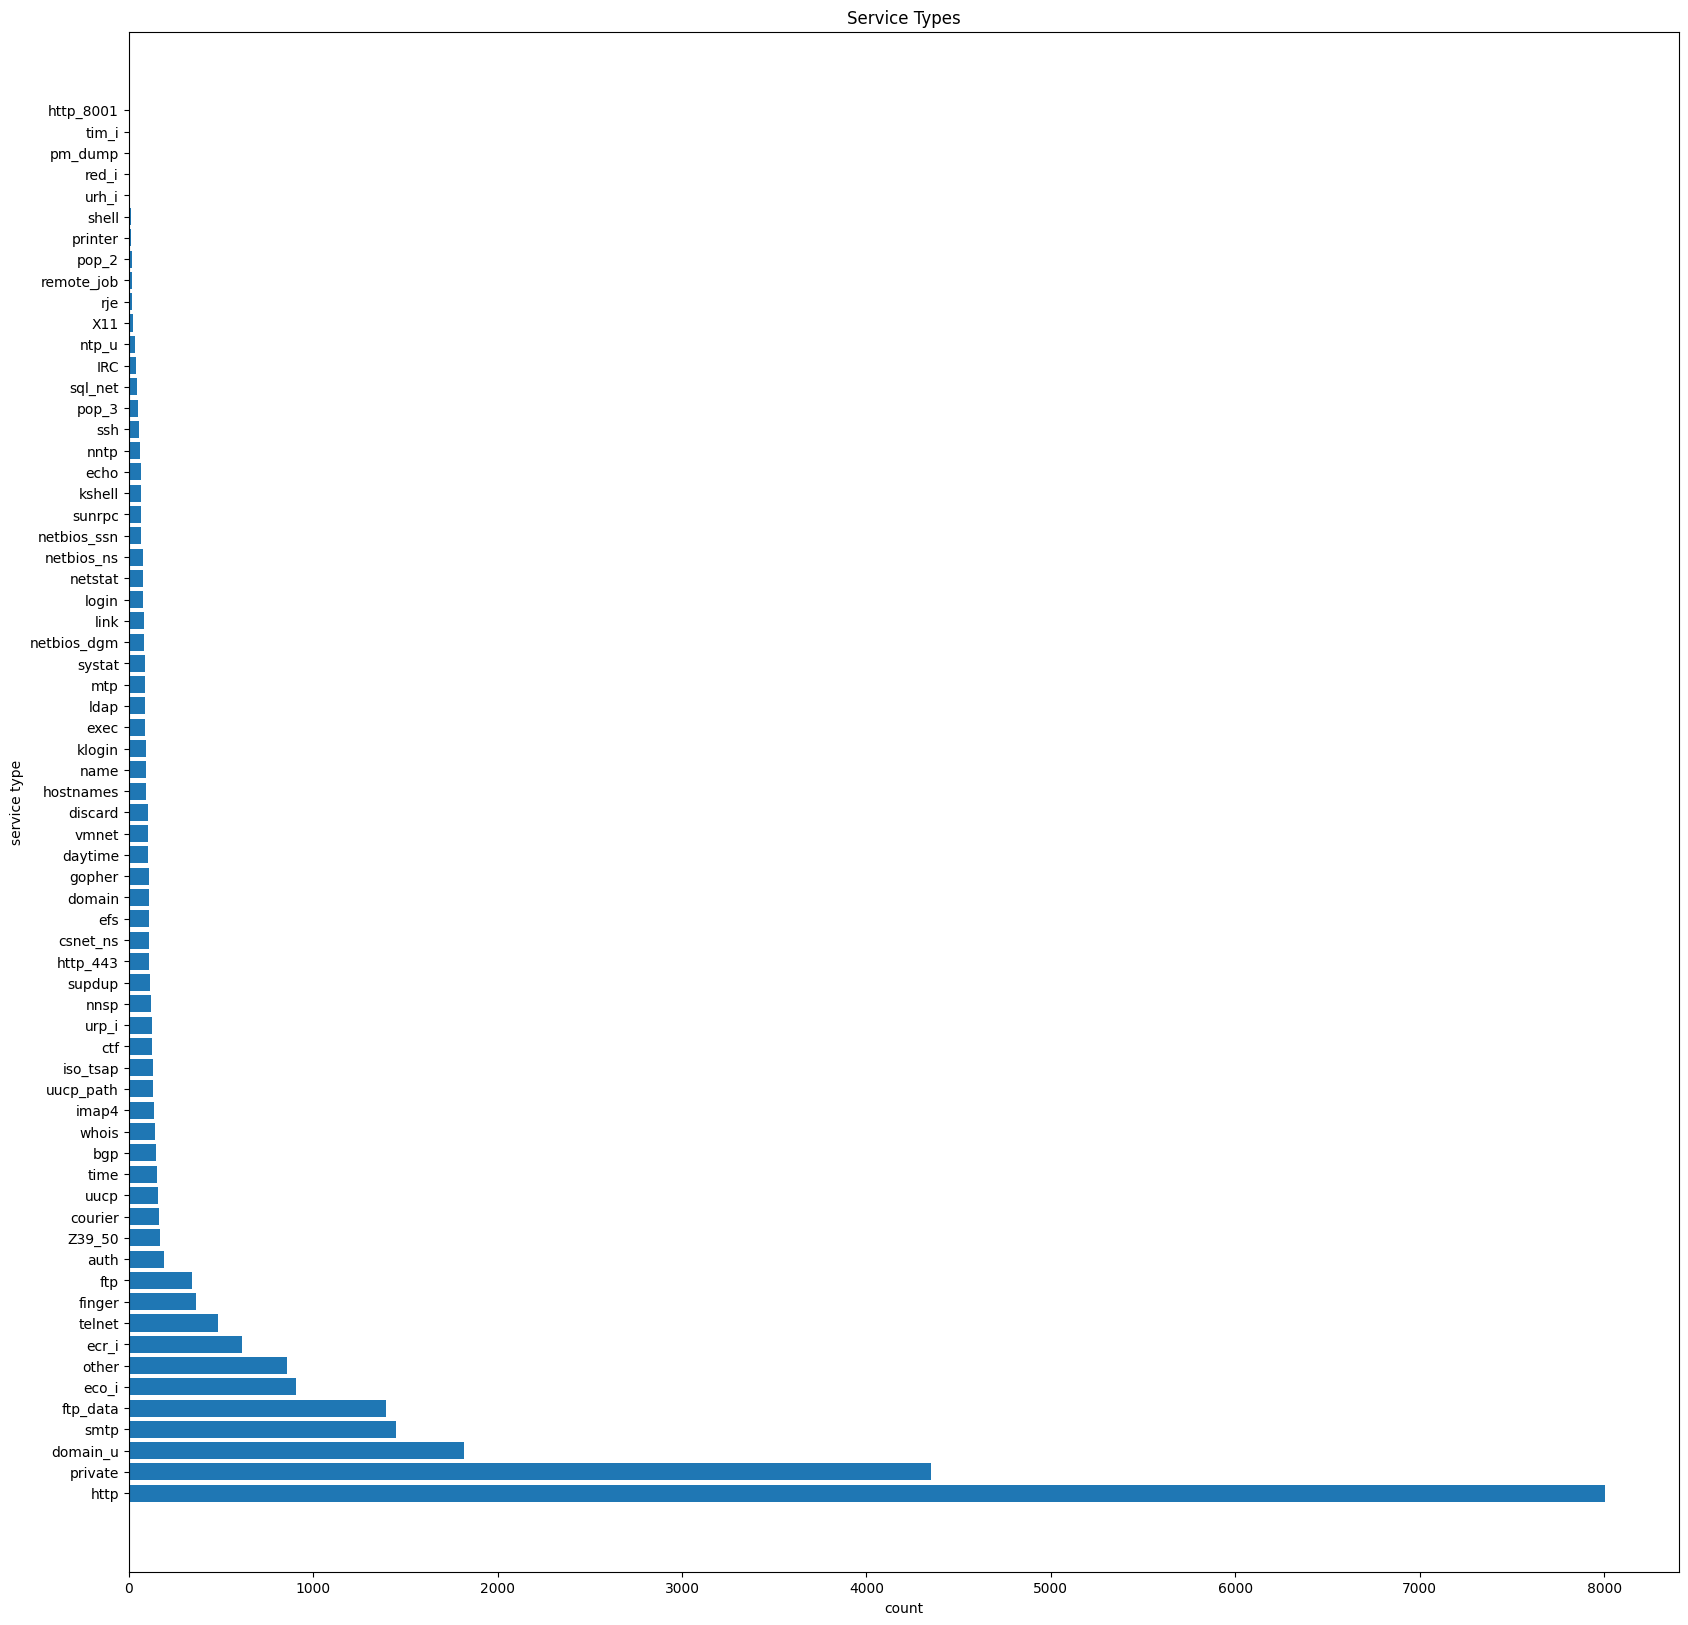

In [9]:
service_dict = df['service'].value_counts().to_dict()

plt.figure(figsize=(20, 20)) 
plt.barh(service_dict.keys(),service_dict.values())
plt.title('Service Types')
plt.xlabel('count')
plt.ylabel('service type')

Text(0, 0.5, 'count')

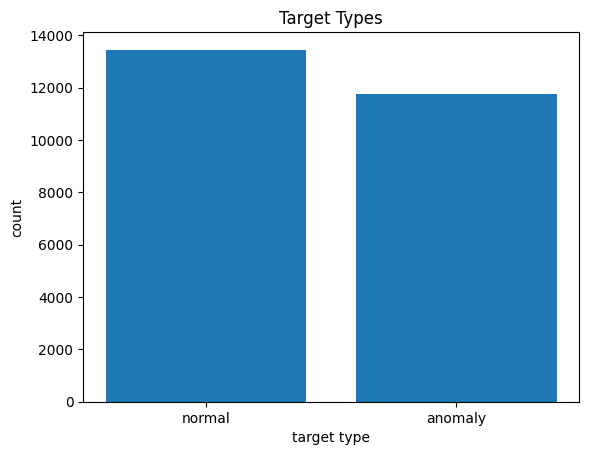

In [10]:
class_dict = df['class'].value_counts().to_dict()
plt.bar(class_dict.keys(),class_dict.values())
plt.title('Target Types')
plt.xlabel('target type')
plt.ylabel('count')

# Encoding

In [11]:
service_freq = df['service'].value_counts()
flag_freq = df['flag'].value_counts()

In [12]:
from sklearn.preprocessing import LabelEncoder

protocol_type_le = LabelEncoder()

In [13]:
df['protocol_type'] = protocol_type_le.fit_transform(df['protocol_type'])
df['service'] = df['service'].map(service_freq)
df['flag'] = df['flag'].map(flag_freq)

In [14]:
df.head(10)

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,class
0,0,1,1396,14973,491,0,0,0,0,0,...,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal
1,0,2,858,14973,146,0,0,0,0,0,...,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal
2,0,1,4351,7009,0,0,0,0,0,0,...,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,anomaly
3,0,1,8003,14973,232,8153,0,0,0,0,...,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal
4,0,1,8003,14973,199,420,0,0,0,0,...,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal
5,0,1,4351,2216,0,0,0,0,0,0,...,19,0.07,0.07,0.00,0.00,0.00,0.00,1.00,1.00,anomaly
6,0,1,4351,7009,0,0,0,0,0,0,...,9,0.04,0.05,0.00,0.00,1.00,1.00,0.00,0.00,anomaly
7,0,1,4351,7009,0,0,0,0,0,0,...,15,0.06,0.07,0.00,0.00,1.00,1.00,0.00,0.00,anomaly
8,0,1,17,7009,0,0,0,0,0,0,...,23,0.09,0.05,0.00,0.00,1.00,1.00,0.00,0.00,anomaly
9,0,1,4351,7009,0,0,0,0,0,0,...,13,0.05,0.06,0.00,0.00,1.00,1.00,0.00,0.00,anomaly


In [15]:
df['class'].value_counts()

class
normal     13449
anomaly    11743
Name: count, dtype: int64

In [16]:
df['class'] = df['class'].map({'normal':0,'anomaly':1})

In [14]:
df.head(10)

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,class
0,0,1,1396,14973,491,0,0,0,0,0,...,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,0
1,0,2,858,14973,146,0,0,0,0,0,...,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,0
2,0,1,4351,7009,0,0,0,0,0,0,...,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,1
3,0,1,8003,14973,232,8153,0,0,0,0,...,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,0
4,0,1,8003,14973,199,420,0,0,0,0,...,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0
5,0,1,4351,2216,0,0,0,0,0,0,...,19,0.07,0.07,0.00,0.00,0.00,0.00,1.00,1.00,1
6,0,1,4351,7009,0,0,0,0,0,0,...,9,0.04,0.05,0.00,0.00,1.00,1.00,0.00,0.00,1
7,0,1,4351,7009,0,0,0,0,0,0,...,15,0.06,0.07,0.00,0.00,1.00,1.00,0.00,0.00,1
8,0,1,17,7009,0,0,0,0,0,0,...,23,0.09,0.05,0.00,0.00,1.00,1.00,0.00,0.00,1
9,0,1,4351,7009,0,0,0,0,0,0,...,13,0.05,0.06,0.00,0.00,1.00,1.00,0.00,0.00,1


In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25192 entries, 0 to 25191
Data columns (total 42 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   duration                     25192 non-null  int64  
 1   protocol_type                25192 non-null  int32  
 2   service                      25192 non-null  int64  
 3   flag                         25192 non-null  int64  
 4   src_bytes                    25192 non-null  int64  
 5   dst_bytes                    25192 non-null  int64  
 6   land                         25192 non-null  int64  
 7   wrong_fragment               25192 non-null  int64  
 8   urgent                       25192 non-null  int64  
 9   hot                          25192 non-null  int64  
 10  num_failed_logins            25192 non-null  int64  
 11  logged_in                    25192 non-null  int64  
 12  num_compromised              25192 non-null  int64  
 13  root_shell      

# Scaling the Dataset(mean=0,stddev=1)

In [18]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
num_cols = df.iloc[:, 0:40].select_dtypes(include=['number']).columns

df[num_cols] = scaler.fit_transform(df[num_cols])

In [19]:
y = df.iloc[:, 41]      
X = df.iloc[:, 0:41]  

In [20]:
from sklearn.model_selection import train_test_split as tts

X_train, X_test, y_train, y_test = tts(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

## Logistic Regression

In [21]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train,y_train)

LogisticRegression(max_iter=1000)

In [22]:
from sklearn.metrics import classification_report,confusion_matrix,accuracy_score

y_pred = lr.predict(X_test)

Accuracy: 95.17
Model Report: 
              precision    recall  f1-score   support

           0       0.95      0.96      0.95      4035
           1       0.95      0.94      0.95      3523

    accuracy                           0.95      7558
   macro avg       0.95      0.95      0.95      7558
weighted avg       0.95      0.95      0.95      7558



<Axes: >

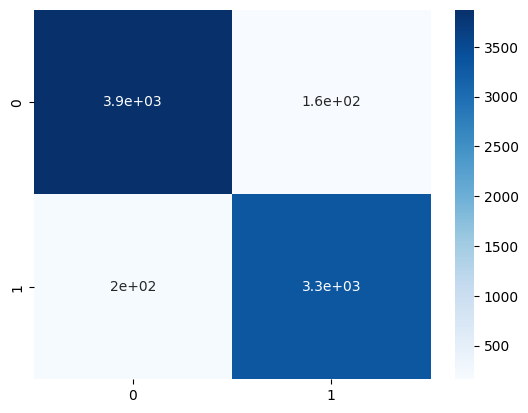

In [23]:
import seaborn as sns


print(f'Accuracy: {accuracy_score(y_test,y_pred)*100:.2f}')
print("Model Report: ")
print(classification_report(y_test,y_pred))

cm = confusion_matrix(y_test,y_pred)

sns.heatmap(cm,annot=True,cmap='Blues')

## Support Vector Classifier

In [24]:
from sklearn.svm import SVC
svc = SVC(kernel='rbf',random_state=42)
svc.fit(X_train,y_train)

SVC(random_state=42)

In [25]:
y_pred_svc = svc.predict(X_test)

In [26]:

print(f'Accuracy : {accuracy_score(y_test,y_pred_svc)*100:.2f}')
print("Model Report: ")
print(classification_report(y_test,y_pred_svc))

Accuracy : 98.85
Model Report: 
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      4035
           1       0.99      0.99      0.99      3523

    accuracy                           0.99      7558
   macro avg       0.99      0.99      0.99      7558
weighted avg       0.99      0.99      0.99      7558



## GaussianNB

In [27]:
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()

In [25]:
gnb.fit(X_train,y_train)

GaussianNB()

In [26]:
y_pred_gnb = gnb.predict(X_test)

print(f'Accuracy : {accuracy_score(y_test,y_pred_gnb)*100:.2f}')
print("Model Report: ")
print(classification_report(y_test,y_pred_gnb))

Accuracy : 89.18
Model Report: 
              precision    recall  f1-score   support

           0       0.93      0.86      0.89      4035
           1       0.85      0.93      0.89      3523

    accuracy                           0.89      7558
   macro avg       0.89      0.89      0.89      7558
weighted avg       0.89      0.89      0.89      7558



## Decision Tree

In [27]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier()
dt.fit(X_train,y_train)

DecisionTreeClassifier()

In [28]:
y_pred_dt = dt.predict(X_test)

print(f'Accuracy : {accuracy_score(y_test,y_pred_dt)*100:.2f}')
print("Model Report: ")
print(classification_report(y_test,y_pred_dt))

Accuracy : 99.48
Model Report: 
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4035
           1       0.99      0.99      0.99      3523

    accuracy                           0.99      7558
   macro avg       0.99      0.99      0.99      7558
weighted avg       0.99      0.99      0.99      7558



# MLP

In [32]:
from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(
    hidden_layer_sizes=(64,32),
    activation='relu',
    solver='adam',
    alpha=0.01,
    learning_rate='adaptive',
    max_iter=500,
    batch_size=64,
    early_stopping=True
)

In [33]:
mlp.fit(X_train,y_train)

MLPClassifier(alpha=0.01, batch_size=64, early_stopping=True,
              hidden_layer_sizes=(64, 32), learning_rate='adaptive',
              max_iter=500)

In [34]:
y_mlp_pred = mlp.predict(X_test)

In [35]:
print(f'Accuracy : {accuracy_score(y_test,y_mlp_pred)*100:.2f}')
print("Model Report: ")
print(classification_report(y_test,y_mlp_pred))

Accuracy : 99.29
Model Report: 
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      4035
           1       0.99      0.99      0.99      3523

    accuracy                           0.99      7558
   macro avg       0.99      0.99      0.99      7558
weighted avg       0.99      0.99      0.99      7558



# Ensembles (RandomForest,XGBoost,LightGBM)

## Random Forest

In [36]:
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier

rf = RandomForestClassifier()
gbcls = GradientBoostingClassifier()

In [37]:
rf.fit(X_train,y_train)

RandomForestClassifier()

## Gradient Boosting

In [38]:
gbcls.fit(X_train,y_train)

GradientBoostingClassifier()

In [39]:
y_pred_rf = rf.predict(X_test)
y_pred_gbcls = gbcls.predict(X_test)

In [40]:
print(f'Accuracy : {accuracy_score(y_test,y_pred_rf)*100:.2f}')
print("Model Report: ")
print(classification_report(y_test,y_pred_rf))

Accuracy : 99.66
Model Report: 
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      4035
           1       1.00      0.99      1.00      3523

    accuracy                           1.00      7558
   macro avg       1.00      1.00      1.00      7558
weighted avg       1.00      1.00      1.00      7558



In [41]:
print(f'Accuracy : {accuracy_score(y_test,y_pred_gbcls)*100:.2f}')
print("Model Report: ")
print(classification_report(y_test,y_pred_gbcls))

Accuracy : 99.51
Model Report: 
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      4035
           1       1.00      0.99      0.99      3523

    accuracy                           1.00      7558
   macro avg       1.00      1.00      1.00      7558
weighted avg       1.00      1.00      1.00      7558



# XGBoost

In [53]:
from xgboost import XGBClassifier


xgb = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss'
)

xgb.fit(X_train, y_train)

y_pred_xgb = xgb.predict(X_test)

print("XGBoost Accuracy:", accuracy_score(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb))


XGBoost Accuracy: 0.9970891770309606
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4035
           1       1.00      0.99      1.00      3523

    accuracy                           1.00      7558
   macro avg       1.00      1.00      1.00      7558
weighted avg       1.00      1.00      1.00      7558



## LightGBM

In [51]:
from lightgbm import LGBMClassifier

lgbm = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.02,
    max_depth=-1,   
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary'
)

lgbm.fit(X_train, y_train)

y_pred_lgbm = lgbm.predict(X_test)

print("LightGBM Accuracy:", accuracy_score(y_test, y_pred_lgbm))
print(classification_report(y_test, y_pred_lgbm))


[LightGBM] [Info] Number of positive: 8220, number of negative: 9414
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.004363 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2761
[LightGBM] [Info] Number of data points in the train set: 17634, number of used features: 34
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.466145 -> initscore=-0.135628
[LightGBM] [Info] Start training from score -0.135628
LightGBM Accuracy: 0.9974861074358295
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4035
           1       1.00      1.00      1.00      3523

    accuracy                           1.00      7558
   macro avg       1.00      1.00      1.00      7558
weighted avg       1.00      1.00      1.00      7558



# Conclusions

**Tree Based Models work good on tabular data(classification tasks)**

In [58]:
model_accuracies = {
    "LogisticRegression": round(accuracy_score(y_test, y_pred) * 100, 2),
    "SupportVectorClassifier": round(accuracy_score(y_test, y_pred_svc) * 100, 2),
    "GaussianNB": round(accuracy_score(y_test, y_pred_gnb) * 100, 2),
    "DecisionTree": round(accuracy_score(y_test, y_pred_dt) * 100, 2),
    "MultiLayerPerceptron": round(accuracy_score(y_test, y_mlp_pred) * 100, 2),
    "RandomForest": round(accuracy_score(y_test, y_pred_rf) * 100, 2),
    "GradientBoostingClf": round(accuracy_score(y_test, y_pred_gbcls) * 100, 2),
    "XGBoost": round(accuracy_score(y_test, y_pred_xgb) * 100, 2),
    "LightGBM": round(accuracy_score(y_test, y_pred_lgbm) * 100, 2)
}


sorted_model_accuracies = dict(sorted(model_accuracies.items(), key=lambda x: x[1], reverse=True))
sorted_model_accuracies


{'LightGBM': 99.75,
 'XGBoost': 99.71,
 'RandomForest': 99.66,
 'GradientBoostingClf': 99.51,
 'DecisionTree': 99.48,
 'MultiLayerPerceptron': 99.29,
 'SupportVectorClassifier': 98.85,
 'LogisticRegression': 95.17,
 'GaussianNB': 89.18}

In [77]:
import numpy as np
colors = plt.cm.RdYlGn(np.linspace(0, 1, len(accuracies)))
colors = colors[::-1]

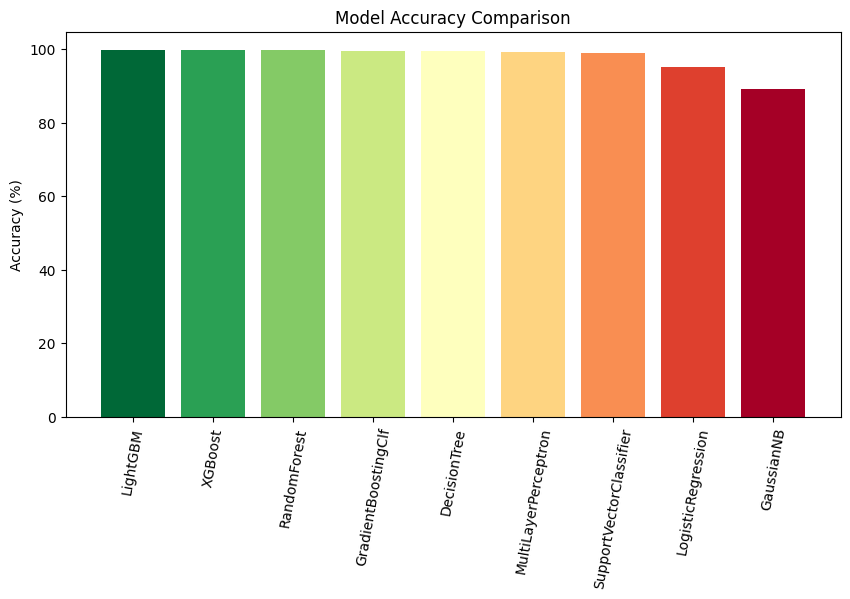

In [81]:
plt.figure(figsize=(10, 5))
plt.bar(sorted_model_accuracies.keys(), sorted_model_accuracies.values(),color=colors)
plt.xticks(rotation=80)
plt.ylabel("Accuracy (%)")
plt.title("Model Accuracy Comparison")
plt.show()
